In [2]:
import seaborn as sns

import pandas as pd

In [3]:
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")


In [4]:
print("First 5 rows:")
print(df.head())


First 5 rows:
               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Si

In [5]:
print(df.shape)


(6433, 14)


In [6]:
print(df.columns)

Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='object')


In [7]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_zone      6407 non-null   object        
 11  dropoff_zone     6388 non-null   object        
 12  pickup_borough   6407 non-null   object        
 13  dropoff_borough  6388 non-null   object        
dtypes: datetime64[ns](2), float64(5), int64(

In [8]:
print(df.describe())

                              pickup                        dropoff  \
count                           6433                           6433   
mean   2019-03-16 08:31:28.514223616  2019-03-16 08:45:49.491217408   
min              2019-02-28 23:29:03            2019-02-28 23:32:35   
25%              2019-03-08 15:50:34            2019-03-08 16:12:51   
50%              2019-03-15 21:46:58            2019-03-15 22:06:44   
75%              2019-03-23 17:41:38            2019-03-23 17:51:56   
max              2019-03-31 23:43:45            2019-04-01 00:13:58   
std                              NaN                            NaN   

        passengers     distance         fare         tip        tolls  \
count  6433.000000  6433.000000  6433.000000  6433.00000  6433.000000   
mean      1.539251     3.024617    13.091073     1.97922     0.325273   
min       0.000000     0.000000     1.000000     0.00000     0.000000   
25%       1.000000     0.980000     6.500000     0.00000     0.00000

In [9]:
print("Missing values before cleaning:")
print(df.isnull().sum())


Missing values before cleaning:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [10]:
## Remove rows with missing critical timestamps were removed to maintain data integrity.
df = df.dropna(subset=["pickup", "dropoff"])


In [11]:
## Identify numerical and categorical columns
numerical_columns = df.select_dtypes(include="number").columns
categorical_columns = df.select_dtypes(include=["object", "category"]).columns


In [12]:
# Fill missing numerical values with the median
for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with the mode
for col in categorical_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])


In [13]:
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nCleaned dataset shape:", df.shape)

print("\nFirst 5 rows of cleaned data:")
print(df.head())


Missing values after cleaning:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

Cleaned dataset shape: (6433, 14)

First 5 rows of cleaned data:
               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill We

In [14]:
## Visualizations using Matplotlib/Pandas Plot:

import matplotlib.pyplot as plt


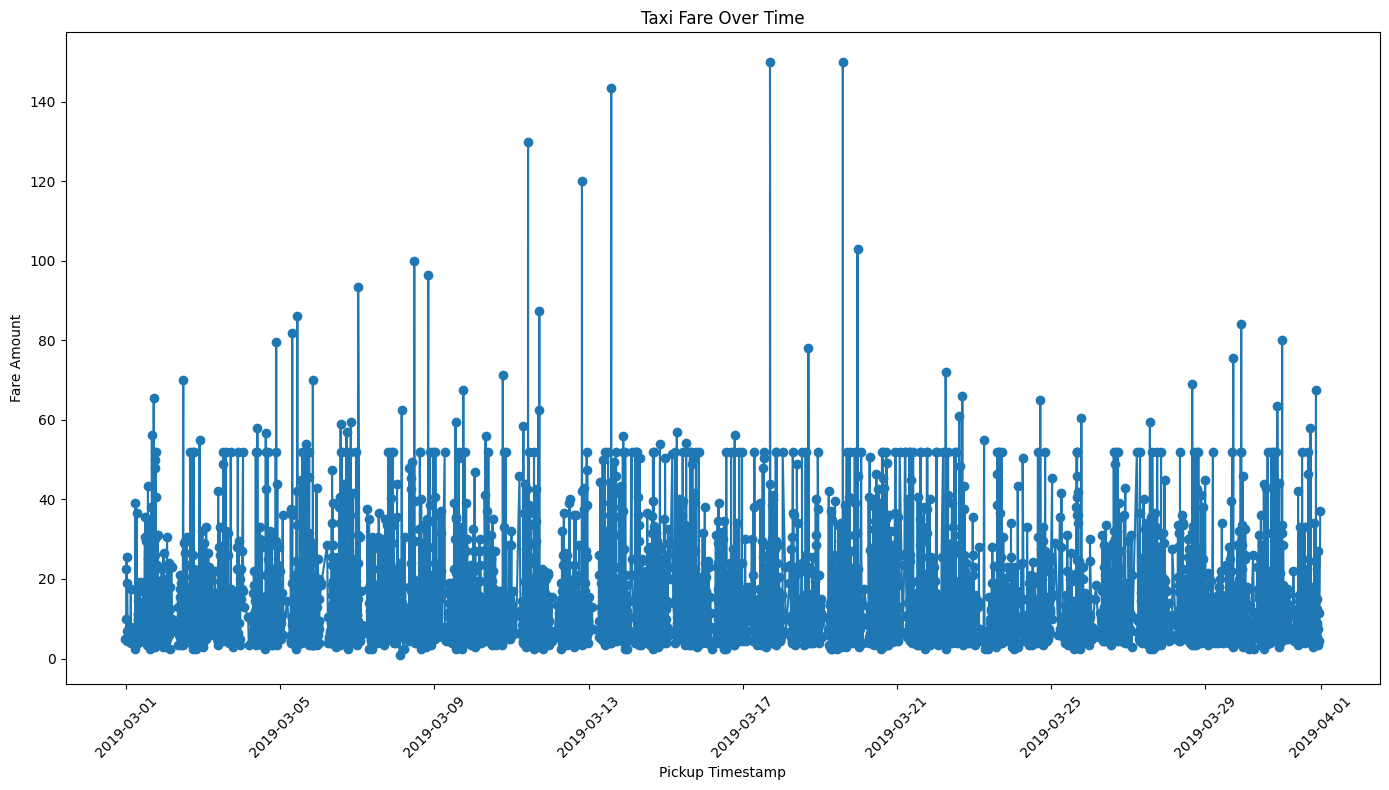

In [15]:
## 1. Line Chart — Fare Over Time

df["pickup"] = pd.to_datetime(df["pickup"])

# Sort data by pickup timestamp
df = df.sort_values("pickup")

# Plot line chart
plt.figure(figsize=(14, 8))
plt.plot(df["pickup"], df["fare"], marker="o")

plt.title("Taxi Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare Amount")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


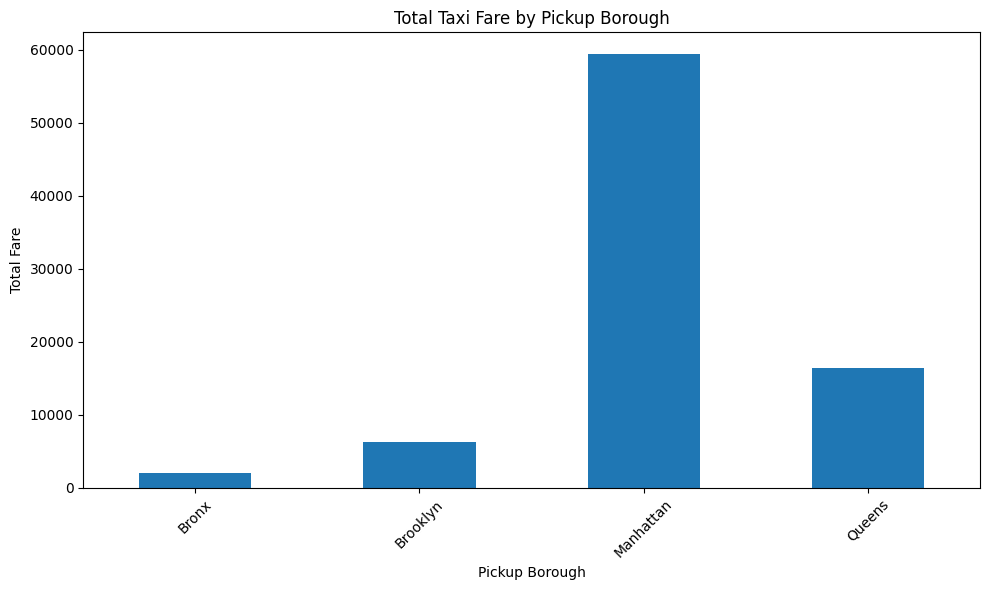

In [16]:
## 2. Bar Chart — Total Fare by Pickup Borough

# Remove rows with missing pickup borough or fare
df_clean = df.dropna(subset=["pickup_borough", "fare"])

# Calculate total fare for each pickup borough
borough_fare = df_clean.groupby("pickup_borough")["fare"].sum()


## Create bar chart
plt.figure(figsize=(10, 6))
borough_fare.plot(kind="bar")

plt.title("Total Taxi Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


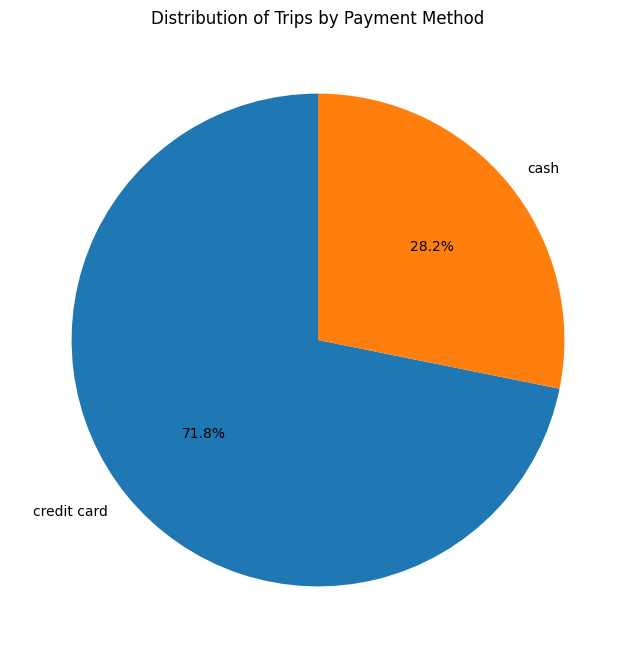

In [17]:
## 3. Pie Chart — Trips by Payment Method

# Count trips for each payment method
payment_counts = df["payment"].value_counts()

# Create a pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90 )

plt.title("Distribution of Trips by Payment Method")

plt.show()


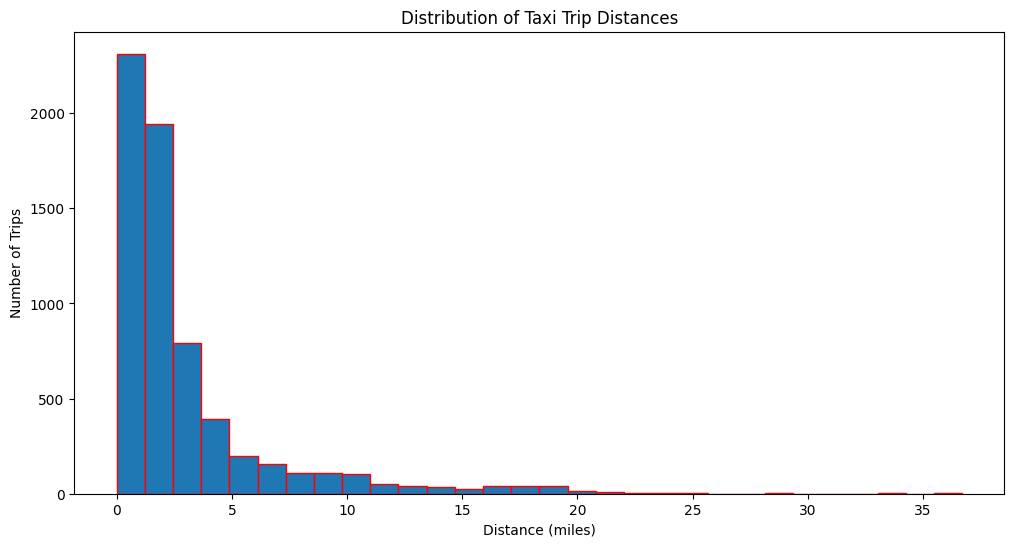

In [21]:
## 4. Histogram — Distribution of Taxi Trip Distance

# Create a histogram of trip distances

plt.figure(figsize=(12, 6))
plt.hist(df["distance"].dropna(), bins=30, edgecolor="red")

plt.title("Distribution of Taxi Trip Distances")
plt.xlabel("Distance (miles)")
plt.ylabel("Number of Trips")

plt.show()

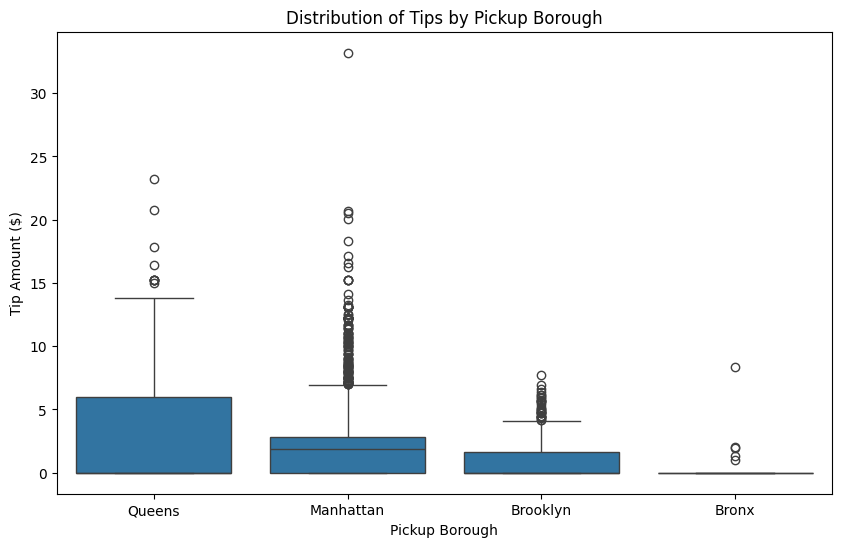

In [22]:
## 5.Box Plot — Tip Amount by Pickup Borough

# it Removes rows with missing borough or tip values
df_clean = df.dropna(subset=["pickup_borough", "tip"])

# Create a box plot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x="pickup_borough", y="tip")

plt.title("Distribution of Tips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount ($)")

plt.show()


In [23]:
## Visualizations using Seaborn:
import seaborn as sns
import matplotlib.pyplot as plt

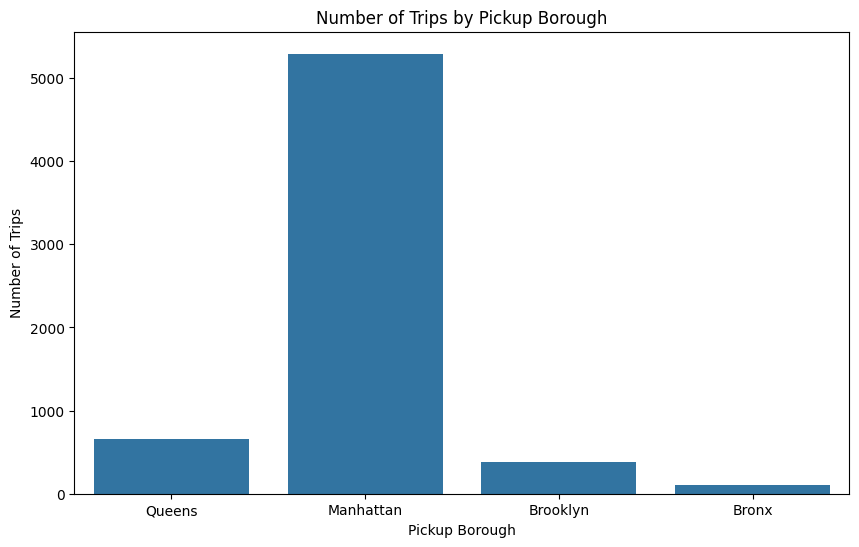

In [24]:
## 1. Count Plot — Number of Trips by Pickup Borough

# Create a count plot
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="pickup_borough")   ## sns.countplot()- Counts the number of observations in each category.

plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")

plt.show()


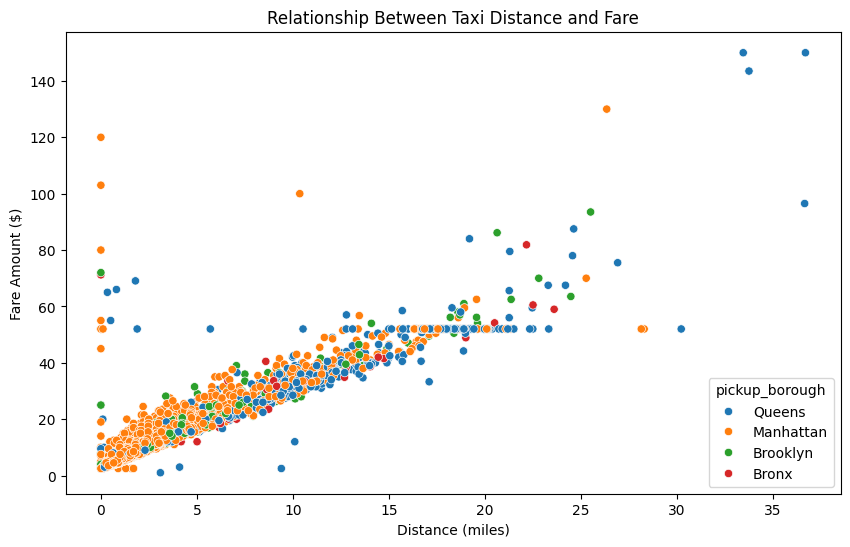

In [25]:
## 2. Scatter Plot — Relationship Between Distance and Fare

# Remove rows with missing values in required columns
df_clean = df.dropna(subset=["distance", "fare", "pickup_borough"])

# Create a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clean,
    x="distance",
    y="fare",
    hue="pickup_borough" )

plt.title("Relationship Between Taxi Distance and Fare")
plt.xlabel("Distance (miles)")
plt.ylabel("Fare Amount ($)")

plt.show()


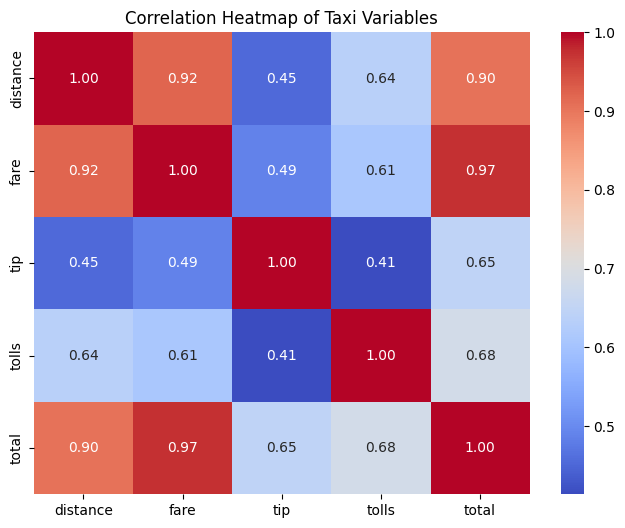

In [28]:
## 3. Heatmap — Correlation Between Numerical Variables

# Select numerical columns
numerical_data = df[["distance", "fare", "tip", "tolls", "total"]] ## this Selects the five numerical variables.

# Calculate the correlation matrix
correlation_matrix = numerical_data.corr()  # it Calculates the correlation between each pair of variables.

# Create the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm", fmt=".2f" )   ## fmt=".2f"- it Displays values to two decimal places.

plt.title("Correlation Heatmap of Taxi Variables")

plt.show()


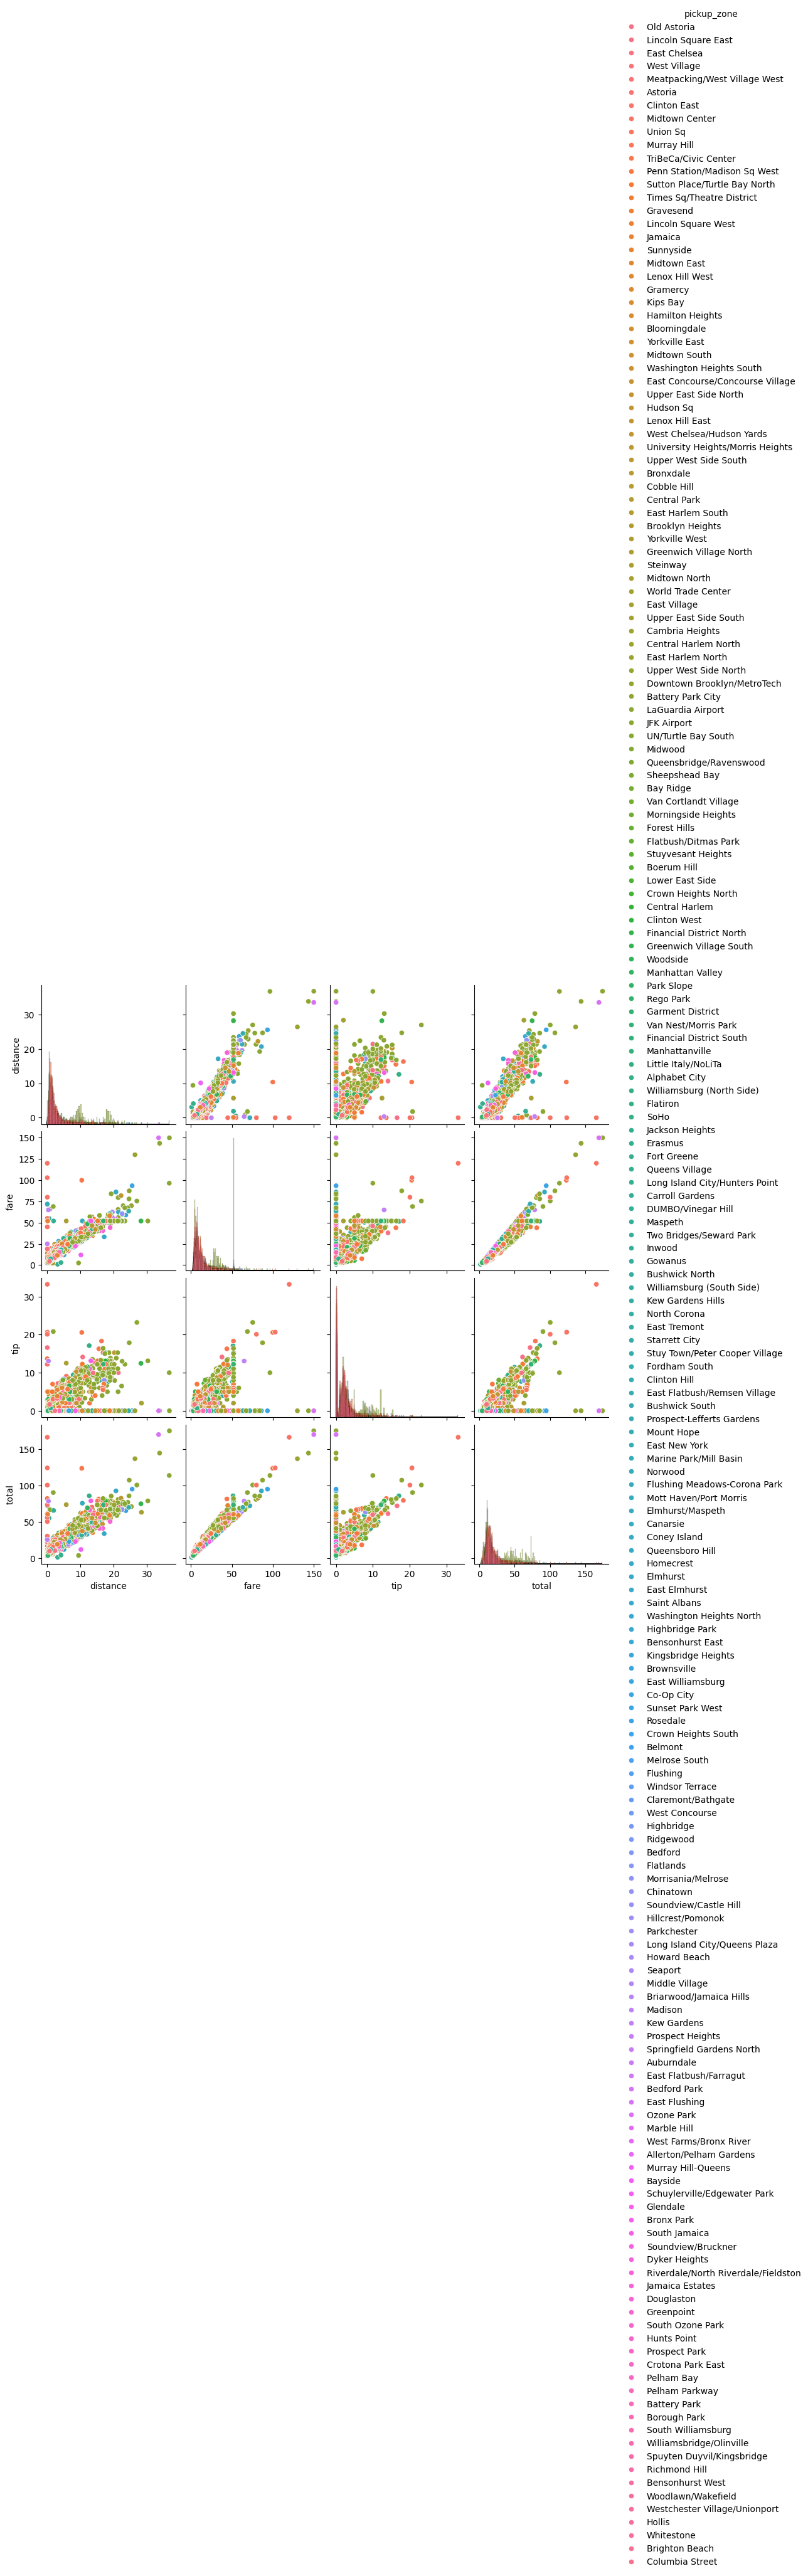

In [29]:
## 4.Pair Plot — Relationships Between Taxi Variables

## Select the required columns and remove missing values

top_zones = df["pickup_zone"].value_counts().head(10).index

pair_data = df[ df["pickup_zone"].isin(top_zones)
][["distance", "fare", "tip", "total", "pickup_zone"] ].dropna()

# Create the pair plot
sns.pairplot(
    data=pair_data,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone",
    diag_kind="hist" )

plt.show()

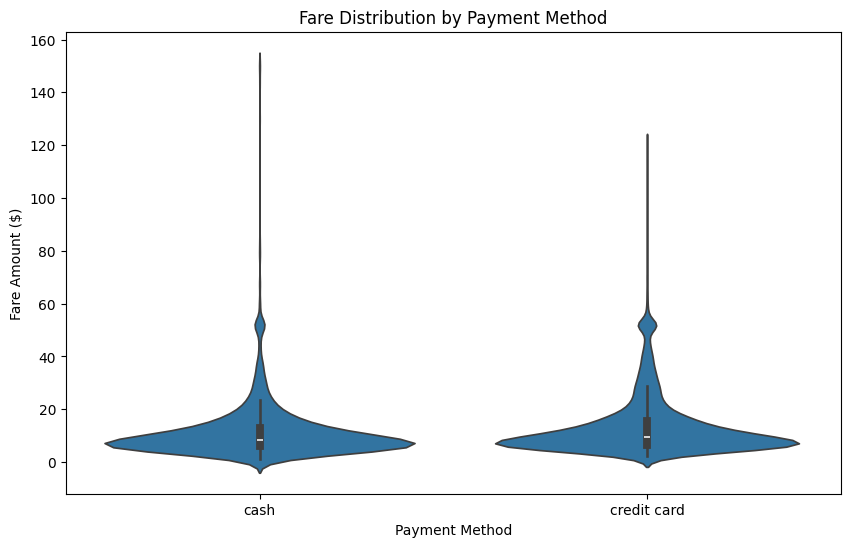

In [30]:
## 5. Violin Plot — Fare Distribution by Payment Method

# Remove rows with missing payment or fare values

violin_data = df.dropna(subset=["payment", "fare"])

# Create the violin plot
plt.figure(figsize=(10, 6))
sns.violinplot( data=violin_data, x="payment", y="fare" )

plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare Amount ($)")

plt.show()
